In [88]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
from qiskit.visualization import plot_bloch_vector
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

from math import sqrt

In [106]:
def converter(alpha, beta, shots = 1024):
  bloch_vector = []

  # State initialization circuit
  qc = QuantumCircuit(1, 1)
  qc.initialize([alpha, beta], [0])

  # measure_x circuit
  measure_x = QuantumCircuit(1, 1)
  measure_x.h(0)
  measure_x.measure([0], [0])
  measure_x = qc.compose(measure_x)

  # measure_y circuit
  measure_y = QuantumCircuit(1, 1)
  measure_y.sdg(0)
  measure_y.h(0)
  measure_y.measure([0], [0])

  # measure_z circuit
  measure_z = QuantumCircuit(1, 1)
  measure_z.measure([0], [0])

  # Measurements
  job = StatevectorSampler().run([qc.compose(measure_x), qc.compose(measure_y), qc.compose(measure_z)], shots=shots)
  result = job.result()

  for i in range(3):
    data = result[i].data
    counts = data.c.get_counts()

    zero_prob = 0
    one_prob = 0

    if "0" in counts:
      zero_prob = counts['0'] / shots
    if "1" in counts:
      one_prob = counts['1'] / shots

    bloch_vector.append(zero_prob - one_prob)

  return bloch_vector

[0.0458984375, 1.0, 0.0048828125]


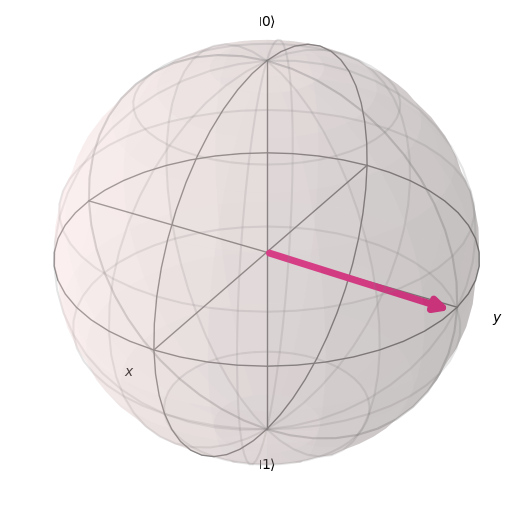

In [107]:
alpha = 1/sqrt(2.0)
beta = complex(0, 1/sqrt(2.0))

bloch_vector = converter(alpha, beta, 4096)
print(bloch_vector)
plot_bloch_vector(bloch_vector)